# AI Methods I 
###### Group Members: Ugochinyere Megwa, Sneha Sachin Shenoy, Álvaro Miñé
###### Faculty: Salvador

## Apartment Cost in New York City

#### Overview

This data was downloaded from Kaggle. Our aim is to analyse the data, clean it, explore it and model it. 



In [ ]:
# %pip install "kagglehub[pandas-datasets]" pandas numpy matplotlib seaborn scikit-learn

In [94]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub as kh
import zipfile
from pathlib import Path
from matplotlib.ticker import FuncFormatter, MaxNLocator

In [95]:
df = pd.read_csv('../figures/apartment_data.csv')

In [96]:
df_clean = df.copy()

In [97]:
print(df)

           Job #    Borough House #          Street Name  Block  Lot    Bin #  \
0      123768976  MANHATTAN    1598           2ND AVENUE   1545   49  1049907   
1      140922893  MANHATTAN     160              E 89 ST   1517   43  1048094   
2      301773579   BROOKLYN      65         GATES AVENUE   1962   86  3056039   
3      301976057   BROOKLYN    1401         OCEAN AVENUE   7584   35  3206621   
4      301989276   BROOKLYN     154         NOBLE STREET   2573   10  3065099   
...          ...        ...     ...                  ...    ...  ...      ...   
19608  122923649  MANHATTAN     315     WEST 33RD STREET    757   22  1013552   
19609  121090112  MANHATTAN     110         DUANE STREET    150   22  1001645   
19610  102937342  MANHATTAN     166          BANK STREET    638    4  1078335   
19611  200838558      BRONX    2762  KINGSBRIDGE TERRACE   3253   90  2015521   
19612  301429158   BROOKLYN     802        HOWARD AVENUE   3565   42  3081797   

      Job Type  Community -

In [98]:
df

,Job #,Borough,House #,Street Name,Block,Lot,Bin #,Job Type,Community - Board,Curb Cut,Fully Permitted,Initial Cost,Proposed Zoning Sqft,Horizontal Enlrgmt,Vertical Enlrgmt,Enlargement SQ Footage,Zoning Dist1,Job Description
0,123768976,MANHATTAN,1598,2ND AVENUE,1545,49,1049907,A2,108,NaN,NaN,"$65,000.00",0,NaN,NaN,0,C1-9,INTERIOR RENOVATION TO COMBINE APARTMENT 2E AN...
1,140922893,MANHATTAN,160,E 89 ST,1517,43,1048094,A2,108,NaN,07/14/2020,"$85,000.00",0,NaN,NaN,0,R8B,HEREBY FILING APPLICATION FOR THE INTERIOR REN...
2,301773579,BROOKLYN,65,GATES AVENUE,1962,86,3056039,A1,302,NaN,05/23/2007,"$60,000.00",0,NaN,NaN,0,R6,Change existing four story and basement brick ...
3,301976057,BROOKLYN,1401,OCEAN AVENUE,7584,35,3206621,A2,314,NaN,02/28/2006,"$75,000.00",0,NaN,NaN,0,NaN,COMBINING OF APARTMENT 4A &amp; 4L.NO CHANGEIN...
4,301989276,BROOKLYN,154,NOBLE STREET,2573,10,3065099,A1,301,NaN,09/29/2006,"$40,000.00",0,NaN,NaN,0,C4-3,New C of O for existing building. New duplex a...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19608,122923649,MANHATTAN,315,WEST 33RD STREET,757,22,1013552,A2,104,NaN,03/21/2017,"$60,000.00",0,NaN,NaN,0,C6-4,RENOVATION OF APARTMENTS 8N &amp; 12A. ARCHITE...
19609,121090112,MANHATTAN,110,DUANE STREET,150,22,1001645,A2,101,NaN,07/17/2012,"$40,000.00",0,NaN,NaN,0,C6-2A,APARTMENT RENVOATION AT APT #4R. DEMOLISH AND ...
19610,102937342,MANHATTAN,166,BANK STREET,638,4,1078335,A2,102,NaN,02/07/2001,"$80,000.00",0,NaN,NaN,0,C6-2,Interior renovation of an existing apartment. ...
19611,200838558,BRONX,2762,KINGSBRIDGE TERRACE,3253,90,2015521,A2,208,NaN,NaN,"$40,000.00",0,NaN,NaN,0,R6,Proposed to renovate existing apartments. No c...


In [99]:
df = df.drop(['Curb Cut', 'Proposed Zoning Sqft', 'Horizontal Enlrgmt', 'Vertical Enlrgmt', 'Enlargement SQ Footage' ], axis=1)


In [100]:
df.isnull().sum(axis=1)

0        1
1        0
2        0
3        1
4        0
        ..
19608    0
19609    0
19610    0
19611    1
19612    1
Length: 19613, dtype: int64

In [101]:
df[df.isnull().sum(axis=1) > 0]

,Job #,Borough,House #,Street Name,Block,Lot,Bin #,Job Type,Community - Board,Fully Permitted,Initial Cost,Zoning Dist1,Job Description
0,123768976,MANHATTAN,1598,2ND AVENUE,1545,49,1049907,A2,108,NaN,"$65,000.00",C1-9,INTERIOR RENOVATION TO COMBINE APARTMENT 2E AN...
3,301976057,BROOKLYN,1401,OCEAN AVENUE,7584,35,3206621,A2,314,02/28/2006,"$75,000.00",NaN,COMBINING OF APARTMENT 4A &amp; 4L.NO CHANGEIN...
11,302022656,BROOKLYN,6,2 STREET,460,2,3007811,A2,306,04/23/2008,"$60,000.00",NaN,RENOVATE EXISTING LOWER DUPLEX APARTMENT. NO C...
12,102614048,MANHATTAN,730,PARK AVENUE,1385,37,1041333,A2,108,05/10/2000,"$75,000.00",NaN,Minor renovation to existing apartment to incl...
13,302026849,BROOKLYN,1054,WILLOUGHBY AVENUE,3208,11,3325441,A2,304,NaN,"$40,000.00",R6,Application being filed to renovate existing s...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
19579,104477870,MANHATTAN,160,CENTRAL PARK SOUTH,1011,7501,1023760,A2,105,09/15/2006,"$85,000.00",NaN,RENOVATION OF AN EXISTING APARTMENTON THE 9TH ...
19583,321998326,BROOKLYN,126,DEAN STREET,194,32,3001265,A1,302,NaN,"$40,000.00",R6,REMOVAL AND INSTALLATION OF INTERIOR PARTITION...
19584,302221138,BROOKLYN,234,WASHINGTON AVENUE,1917,32,3055065,A1,302,NaN,"$75,000.00",R6,Proposed to convert one class 'A' apartment an...
19611,200838558,BRONX,2762,KINGSBRIDGE TERRACE,3253,90,2015521,A2,208,NaN,"$40,000.00",R6,Proposed to renovate existing apartments. No c...


In [102]:
n_duplicates = df_clean.duplicated().sum()
print(n_duplicates)

6104


In [103]:
df = df.drop_duplicates()

In [104]:
df = df.reset_index(drop=True)

In [105]:
df = df.map(lambda x: x.upper() if isinstance(x, str) else x)

In [106]:
df['Initial Cost'] = pd.to_numeric(
    df['Initial Cost']
    .astype('string')
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False),
    errors='coerce'
)

In [107]:
df['Initial Cost Original'] = df['Initial Cost'].copy()

In [108]:
df

,Job #,Borough,House #,Street Name,Block,Lot,Bin #,Job Type,Community - Board,Fully Permitted,Initial Cost,Zoning Dist1,Job Description,Initial Cost Original
0,123768976,MANHATTAN,1598,2ND AVENUE,1545,49,1049907,A2,108,NaN,65000.0,C1-9,INTERIOR RENOVATION TO COMBINE APARTMENT 2E AN...,65000.0
1,140922893,MANHATTAN,160,E 89 ST,1517,43,1048094,A2,108,07/14/2020,85000.0,R8B,HEREBY FILING APPLICATION FOR THE INTERIOR REN...,85000.0
2,301773579,BROOKLYN,65,GATES AVENUE,1962,86,3056039,A1,302,05/23/2007,60000.0,R6,CHANGE EXISTING FOUR STORY AND BASEMENT BRICK ...,60000.0
3,301976057,BROOKLYN,1401,OCEAN AVENUE,7584,35,3206621,A2,314,02/28/2006,75000.0,NaN,COMBINING OF APARTMENT 4A &AMP; 4L.NO CHANGEIN...,75000.0
4,301989276,BROOKLYN,154,NOBLE STREET,2573,10,3065099,A1,301,09/29/2006,40000.0,C4-3,NEW C OF O FOR EXISTING BUILDING. NEW DUPLEX A...,40000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13504,123847409,MANHATTAN,225,CENTRAL PARK WEST,1196,29,1031181,A2,107,06/11/2020,60000.0,R10A,COMBINATION OF APARTMENTS 1608 AND 1610 ON 015...,60000.0
13505,141021631,MANHATTAN,51,5TH AVENUE,569,5,1009275,A2,102,12/09/2022,40000.0,R10,LEVEL 2 RENOVATIONS: PARTIAL REMOVAL OF NON-ST...,40000.0
13506,121090112,MANHATTAN,110,DUANE STREET,150,22,1001645,A2,101,07/17/2012,40000.0,C6-2A,APARTMENT RENVOATION AT APT #4R. DEMOLISH AND ...,40000.0
13507,102937342,MANHATTAN,166,BANK STREET,638,4,1078335,A2,102,02/07/2001,80000.0,C6-2,INTERIOR RENOVATION OF AN EXISTING APARTMENT. ...,80000.0


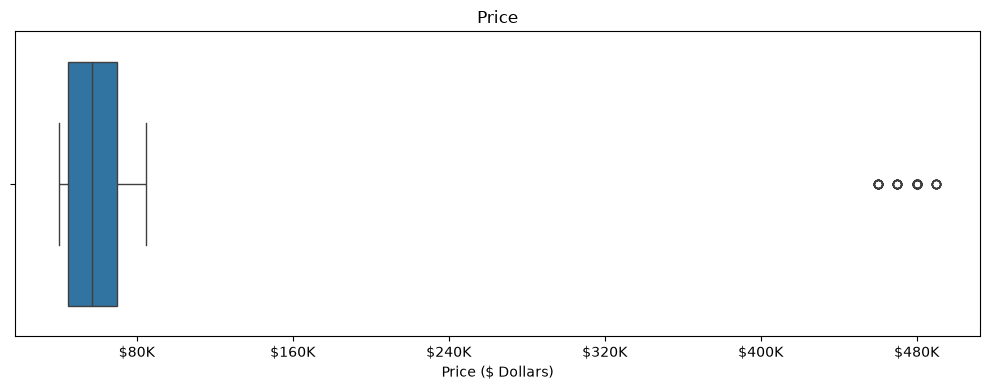

In [62]:
df_clean["Initial Cost"] = pd.to_numeric(
    df_clean["Initial Cost"].astype(str).str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)

fig, ax = plt.subplots(figsize=(10, 4))

sns.boxplot(x=df_clean["Initial Cost"], ax=ax)

ax.set_title("Price")
ax.set_xlabel("Price ($ Dollars)")

# Format tick labels as $65K
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"${x/1000:.0f}K"))

# Limit to roughly 8 ticks
ax.xaxis.set_major_locator(MaxNLocator(nbins=8))

plt.tight_layout()
plt.show()

In [113]:
price = df_clean["Initial Cost"]

# IQR rule
q1, q3 = price.quantile([0.25, 0.75])
iqr = q3 - q1
iqr_outliers = (price < q1 - 1.5 * iqr) | (price > q3 + 1.5 * iqr)
df_clean = df_clean[~iqr_outliers].reset_index(drop=True)
print(f"IQR rule:        keep {q1 - 1.5 * iqr:,.1f} to {q3 + 1.5 * iqr:,.1f} Dollars -> removes {iqr_outliers.sum():,} listings")


IQR rule:        keep 7,500.0 to 107,500.0 Dollars -> removes 59 listings


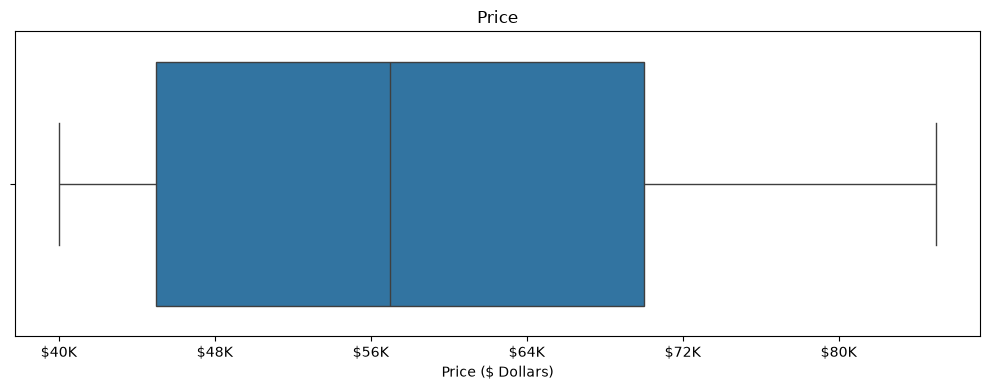

In [114]:
df_clean["Initial Cost"] = pd.to_numeric(
    df_clean["Initial Cost"].astype(str).str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)

fig, ax = plt.subplots(figsize=(10, 4))

sns.boxplot(x=df_clean["Initial Cost"], ax=ax)

ax.set_title("Price")
ax.set_xlabel("Price ($ Dollars)")

# Format tick labels as $65K
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"${x/1000:.0f}K"))

# Limit to roughly 8 ticks
ax.xaxis.set_major_locator(MaxNLocator(nbins=8))

plt.tight_layout()
plt.show()

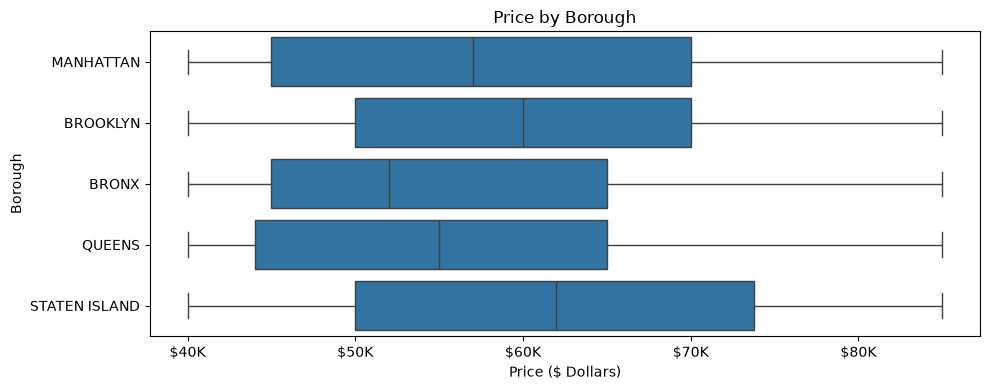

In [115]:
fig, ax = plt.subplots(figsize=(10, 4))

sns.boxplot(data=df_clean, x="Initial Cost", y="Borough", ax=ax)

ax.set_title("Price by Borough")
ax.set_xlabel("Price ($ Dollars)")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"${x/1000:.0f}K"))

plt.tight_layout()
plt.show()

In [116]:
df_clean.columns.tolist()

['Job #',
 'Borough',
 'House #',
 'Street Name',
 'Block',
 'Lot',
 'Bin #',
 'Job Type',
 'Community - Board',
 'Curb Cut',
 'Fully Permitted',
 'Initial Cost',
 'Proposed Zoning Sqft',
 'Horizontal Enlrgmt',
 'Vertical Enlrgmt',
 'Enlargement SQ Footage',
 'Zoning Dist1',
 'Job Description']

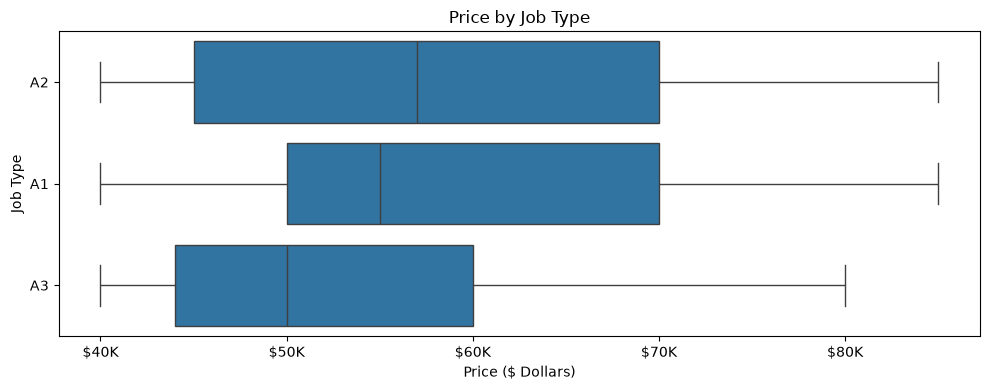

In [117]:
df_clean["Initial Cost"] = pd.to_numeric(
    df_clean["Initial Cost"].astype(str).str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)

fig, ax = plt.subplots(figsize=(10, 4))

sns.boxplot(data=df_clean, x="Initial Cost", y="Job Type", ax=ax)

ax.set_title("Price by Job Type")
ax.set_xlabel("Price ($ Dollars)")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"${x/1000:.0f}K"))

plt.tight_layout()
plt.show()

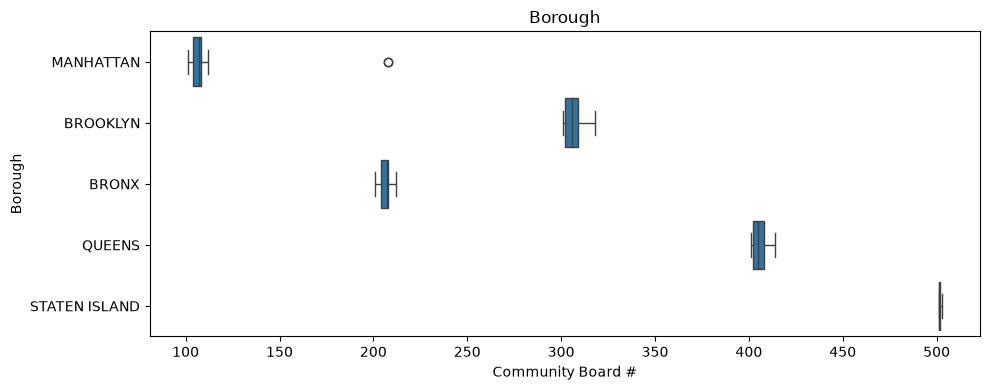

In [123]:
df_clean["Community - Board"] = pd.to_numeric(
    df_clean["Community - Board"].astype(str).str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)

fig, ax = plt.subplots(figsize=(10, 4))

sns.boxplot(data=df_clean, x="Community - Board", y="Borough", ax=ax)

ax.set_title("Borough")
ax.set_xlabel("Community Board #")

plt.tight_layout()
plt.show()

In [118]:
rows_before = len(df_clean)
df_clean = df_clean.dropna(subset=["Initial Cost"]).reset_index(drop=True)
print(f"Removed {rows_before - len(df_clean):,} listings without Initial Cost")

Removed 0 listings without Initial Cost


In [119]:
rows_before = len(df_clean)
df_clean = df_clean.dropna(subset=["Borough"]).reset_index(drop=True)
print(f"Removed {rows_before - len(df_clean):,} listings without Borough")

Removed 0 listings without Borough


In [120]:
df = df.drop_duplicates()
final_columns = [
    # location
    "Job #",
    # size and typology
    "Borough", "House #", "Street Name", "Block", "Lot", "Bin #",
    "Community - Board", "Fully Permitted", "Initial Cost",
    # position in the building
    "Zoning Dist1", "Job Description", 
]

df_clean = df = df.drop_duplicates()[final_columns]
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 13509 entries, 0 to 13508
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Job #              13509 non-null  int64  
 1   Borough            13509 non-null  str    
 2   House #            13509 non-null  str    
 3   Street Name        13509 non-null  str    
 4   Block              13509 non-null  int64  
 5   Lot                13509 non-null  int64  
 6   Bin #              13509 non-null  int64  
 7   Community - Board  13509 non-null  int64  
 8   Fully Permitted    10760 non-null  str    
 9   Initial Cost       13509 non-null  Float64
 10  Zoning Dist1       12047 non-null  str    
 11  Job Description    13509 non-null  str    
dtypes: Float64(1), int64(5), str(6)
memory usage: 1.2 MB
